In [11]:
import os
import time
import gc
import psutil
import pandas as pd
import numpy as np
import xarray as xr
import cupy as cp
from tqdm import tqdm
import pyarrow.parquet as pq
import pyarrow as pa

nc_file = r"F:\TUB\greenlandProject\ERA5LAND\ERA5LANDfeature.nc"
csv_file = r"F:\TUB\greenlandProject\NEWdataverse_files\allsites_albedoYM_lonlai.csv"
result_file = r"F:\TUB\greenlandProject\ERA5LAND\full_interpolated_results.parquet"

# 确保输出目录存在
os.makedirs(os.path.dirname(result_file), exist_ok=True)

def print_memory_usage():
    """打印当前内存使用情况"""
    mem = psutil.virtual_memory()
    print(f"内存使用: {mem.used / (1024 ** 3):.2f} GB / {mem.total / (1024 ** 3):.2f} GB ({mem.percent}%)")

def parse_flexible_date(date_str):
    """智能解析各种日期格式"""
    try:
        return pd.to_datetime(date_str, format='mixed')
    except:
        parts = date_str.split('/')
        year = int(parts[0])
        month = int(parts[1]) if len(parts) > 1 and parts[1] else 1
        day = int(parts[2]) if len(parts) > 2 and parts[2] else 1
        return pd.Timestamp(year=year, month=month, day=day)

def read_station_data():
    """读取站点数据（保留所有记录）"""
    print("正在读取站点数据...")
    df = pd.read_csv(csv_file)
    df['valid_time'] = df['valid_time'].apply(parse_flexible_date)
    df = df.dropna(subset=['valid_time'])
    df['match_month'] = df['valid_time'].dt.to_period('M')
    print(f"站点数据读取完成，共 {len(df)} 条记录")
    return df

def process_data():
    """主处理函数"""
    start_time = time.time()
    print_memory_usage()

    # 1. 读取站点数据
    df = read_station_data()
    print_memory_usage()

    # 2. 打开 NetCDF 数据，使用 Dask 延迟计算
    print("正在打开 NetCDF 文件...")
    ds = xr.open_dataset(nc_file, chunks={'valid_time': 100})
    print("NetCDF 文件打开成功")

    # 处理 NetCDF 时间
    nc_times = pd.to_datetime(ds['valid_time'].values)
    nc_months = pd.Series(nc_times).dt.to_period('M')
    variables = ['asn', 'sp', 'ssrd', 'str', 'strd', 't2m', 'u10', 'v10']

    # 3. 建立索引
    print("建立空间索引...")
    nc_lons = ds['longitude'].values
    nc_lats = ds['latitude'].values

    # 4. 初始化 Parquet writer
    batch_size = 1000
    batch_records = []
    schema = None
    writer = None
    
    # 获取第一个记录以确定schema
    first_record = None
    for idx, row in df.iterrows():
        time_mask = nc_months == row['match_month']
        if time_mask.any():
            time_idx = np.where(time_mask)[0][0]
            lon_idx = cp.argmin(cp.abs(cp.array(nc_lons) - row['longitude'])).get()
            lat_idx = cp.argmin(cp.abs(cp.array(nc_lats) - row['latitude'])).get()
            
            data = ds.isel(valid_time=time_idx)
            first_record = {
                'original_time': row['valid_time'],
                'station': row['station'],
                'longitude': row['longitude'],
                'latitude': row['latitude']
            }
            for var in variables:
                if var in data:
                    first_record[var] = float(data[var].isel(latitude=lat_idx, longitude=lon_idx).astype(np.float32).compute())
            break
    
    if first_record is None:
        print("没有找到匹配的数据!")
        return
    
    # 创建schema
    schema = pa.Schema.from_pandas(pd.DataFrame([first_record]))
    writer = pq.ParquetWriter(result_file, schema, compression='snappy')
    batch_records.append(first_record)

    # 5. 处理剩余记录
    progress = tqdm(df.iloc[1:].iterrows(), total=len(df)-1, desc="处理进度")
    
    for idx, row in progress:
        # 找到匹配的 NetCDF 时间索引
        time_mask = nc_months == row['match_month']
        if not time_mask.any():
            continue
        
        time_idx = np.where(time_mask)[0][0]

        # GPU 计算最近网格点索引
        lon_idx = cp.argmin(cp.abs(cp.array(nc_lons) - row['longitude'])).get()
        lat_idx = cp.argmin(cp.abs(cp.array(nc_lats) - row['latitude'])).get()

        # 提取所有变量
        record = {
            'original_time': row['valid_time'],
            'station': row['station'],
            'longitude': row['longitude'],
            'latitude': row['latitude']
        }

        # 获取 NetCDF 数据（使用 Dask 避免一次性加载）
        data = ds.isel(valid_time=time_idx)
        for var in variables:
            if var in data:
                record[var] = float(data[var].isel(latitude=lat_idx, longitude=lon_idx).astype(np.float32).compute())

        batch_records.append(record)

        # 批量写入 Parquet
        if len(batch_records) >= batch_size:
            table = pa.Table.from_pandas(pd.DataFrame(batch_records), schema=schema)
            writer.write_table(table)
            batch_records.clear()
            gc.collect()
            print_memory_usage()

    # 写入剩余的数据
    if batch_records:
        table = pa.Table.from_pandas(pd.DataFrame(batch_records), schema=schema)
        writer.write_table(table)
    
    # 关闭writer
    if writer:
        writer.close()
    
    print(f"处理完成！结果已保存到 {result_file}")
    print(f"总运行时间: {time.time() - start_time:.2f} 秒")
    print(f"成功处理 {len(df)} 条记录")

if __name__ == '__main__':
    process_data()

内存使用: 10.28 GB / 15.84 GB (64.9%)
正在读取站点数据...
站点数据读取完成，共 4455 条记录
内存使用: 10.32 GB / 15.84 GB (65.1%)
正在打开 NetCDF 文件...
NetCDF 文件打开成功
建立空间索引...


处理进度:  23%|██▎       | 1009/4454 [00:26<01:27, 39.34it/s]

内存使用: 10.44 GB / 15.84 GB (65.9%)


处理进度:  45%|████▌     | 2007/4454 [00:51<01:07, 36.48it/s]

内存使用: 10.36 GB / 15.84 GB (65.4%)


...

内存使用: 10.30 GB / 15.84 GB (65.0%)


处理进度:  90%|████████▉ | 4006/4454 [01:34<00:11, 39.87it/s]

内存使用: 10.31 GB / 15.84 GB (65.1%)


处理进度: 100%|██████████| 4454/4454 [01:45<00:00, 42.23it/s]

处理完成！结果已保存到 F:\TUB\greenlandProject\ERA5LAND\full_interpolated_results.parquet
总运行时间: 106.33 秒
成功处理 4455 条记录


In [12]:
import pandas as pd

# 读取 Parquet 文件
df = pd.read_parquet(r"F:\TUB\greenlandProject\ERA5LAND\full_interpolated_results.parquet")

# 查看前几行
#print(df.head())

# 保存为 CSV
df.to_csv(r"F:\TUB\greenlandProject\ERA5LAND\allfeature.csv", index=False)
print("已转换为 CSV 文件")

已转换为 CSV 文件


In [12]:
import xarray as xr

# 打开nc文件
file_path = r"F:\TUB\greenlandProject\ERA5LAND\snow3para.nc"
dataset = xr.open_dataset(file_path)

# 获取所有变量的 standard_name
standard_names = [var.attrs.get('long_name', 'No standard_name') for var in dataset.variables.values()]

# 打印标准名称
for name in standard_names:
    print(name)


initial time of forecast
latitude
longitude
No standard_name
Snow cover
ensemble member numerical id
Snow depth


In [19]:
import pandas as pd

# 读取 Parquet 文件
df = pd.read_parquet(r"F:\TUB\greenlandProject\ERA5LAND\snow3para.parquet")

# 查看前几行
print(df.head())

# 保存为 CSV
df.to_csv(r"F:\TUB\greenlandProject\ERA5LAND\snow3feature.csv", index=False)
print("已转换为 CSV 文件")

  original_time station  longitude   latitude  snowc        sde
0    1995-06-01     CEN -61.115896  77.181945  100.0  33.333008
1    1995-07-01     CEN -61.115896  77.181945  100.0  33.333008
2    1995-08-01     CEN -61.115896  77.181945  100.0  33.333008
3    1995-09-01     CEN -61.115896  77.181945  100.0  33.333008
4    1996-04-01     CEN -61.115896  77.181945  100.0  33.333008
已转换为 CSV 文件


In [18]:
import pandas as pd

# Load the parquet file
file_path = "F:/TUB/greenlandProject/ERA5LAND/snow3para.parquet"
data = pd.read_parquet(file_path)

# Check for rows where 'snowc' is missing
missing_snowc_rows = data[data['snowc'].isnull()]

# Display the rows with missing 'snowc' data
print(missing_snowc_rows)


Empty DataFrame
Columns: [original_time, station, longitude, latitude, snowc, sde]
Index: []


In [17]:
#成功nc文件经度转换，并提取了snow的两个参数
import os
import time
import gc
import psutil
import pandas as pd
import numpy as np
import xarray as xr
import cupy as cp
from tqdm import tqdm
import pyarrow.parquet as pq
import pyarrow as pa

nc_file = r"F:\TUB\greenlandProject\ERA5LAND\snow3para.nc"  # 修改为新的NetCDF文件路径
csv_file = r"F:\TUB\greenlandProject\NEWdataverse_files\allsites_albedoYM_lonlai.csv"
result_file = r"F:\TUB\greenlandProject\ERA5LAND\snow3para.parquet"

# 确保输出目录存在
os.makedirs(os.path.dirname(result_file), exist_ok=True)

def print_memory_usage():
    """打印当前内存使用情况"""
    mem = psutil.virtual_memory()
    print(f"内存使用: {mem.used / (1024 ** 3):.2f} GB / {mem.total / (1024 ** 3):.2f} GB ({mem.percent}%)")

def parse_flexible_date(date_str):
    """智能解析各种日期格式"""
    try:
        return pd.to_datetime(date_str, format='mixed')
    except:
        parts = date_str.split('/')
        year = int(parts[0])
        month = int(parts[1]) if len(parts) > 1 and parts[1] else 1
        day = int(parts[2]) if len(parts) > 2 and parts[2] else 1
        return pd.Timestamp(year=year, month=month, day=day)

def read_station_data():
    """读取站点数据（保留所有记录）"""
    print("正在读取站点数据...")
    df = pd.read_csv(csv_file)
    df['valid_time'] = df['valid_time'].apply(parse_flexible_date)
    df = df.dropna(subset=['valid_time'])
    df['match_month'] = df['valid_time'].dt.to_period('M')
    print(f"站点数据读取完成，共 {len(df)} 条记录")
    return df

def convert_longitude(nc_lons):
    """
    将 NetCDF 文件中的经度（假设其范围是 280 到 355）转换为 -80 到 -5 范围
    """
    # 将 280 到 355 范围的经度转换为 -80 到 -5
    return ((nc_lons - 360) + 80) % 360 - 80

def process_data():
    """主处理函数"""
    start_time = time.time()
    print_memory_usage()

    # 1. 读取站点数据
    df = read_station_data()
    print_memory_usage()

    # 2. 打开 NetCDF 数据，使用 Dask 延迟计算
    print("正在打开 NetCDF 文件...")
    ds = xr.open_dataset(nc_file, chunks={'valid_time': 100})
    print("NetCDF 文件打开成功")

    # 查看 NetCDF 经度数据并进行转换
    nc_lons = ds['longitude'].values
    nc_lats = ds['latitude'].values
    print(f"原始 NetCDF 经度范围：{nc_lons.min()} 到 {nc_lons.max()}")
    
    # 如果经度范围是 280 到 355，转换为 -80 到 -5
    nc_lons = convert_longitude(nc_lons)
    print(f"转换后的 NetCDF 经度范围：{nc_lons.min()} 到 {nc_lons.max()}")

    # 处理 NetCDF 时间
    nc_times = pd.to_datetime(ds['valid_time'].values)
    nc_months = pd.Series(nc_times).dt.to_period('M')
    variables = ['snowc', 'sde']  # 修改为提取雪覆盖和雪深

    # 3. 建立索引
    print("建立空间索引...")
    
    # 4. 初始化 Parquet writer
    batch_size = 1000
    batch_records = []
    schema = None
    writer = None
    
    # 获取第一个记录以确定schema
    first_record = None
    for idx, row in df.iterrows():
        time_mask = nc_months == row['match_month']
        if time_mask.any():
            time_idx = np.where(time_mask)[0][0]
            lon_idx = cp.argmin(cp.abs(cp.array(nc_lons) - row['longitude'])).get()
            lat_idx = cp.argmin(cp.abs(cp.array(nc_lats) - row['latitude'])).get()
            
            data = ds.isel(valid_time=time_idx)
            first_record = {
                'original_time': row['valid_time'],
                'station': row['station'],
                'longitude': row['longitude'],
                'latitude': row['latitude']
            }
            # 检查是否有匹配的变量
            for var in variables:
                if var in data:
                    first_record[var] = float(data[var].isel(latitude=lat_idx, longitude=lon_idx).astype(np.float32).compute())
                else:
                    print(f"警告: 在站点 {row['station']} (经度: {row['longitude']}, 纬度: {row['latitude']}) 没有找到匹配的 {var} 数据")
            break
    
    if first_record is None:
        print("没有找到匹配的数据!")
        return
    
    # 创建schema
    schema = pa.Schema.from_pandas(pd.DataFrame([first_record]))
    writer = pq.ParquetWriter(result_file, schema, compression='snappy')
    batch_records.append(first_record)

    # 5. 处理剩余记录
    progress = tqdm(df.iloc[1:].iterrows(), total=len(df)-1, desc="处理进度")
    
    for idx, row in progress:
        # 找到匹配的 NetCDF 时间索引
        time_mask = nc_months == row['match_month']
        if not time_mask.any():
            print(f"警告: 站点 {row['station']} (经度: {row['longitude']}, 纬度: {row['latitude']}) 没有找到匹配的时间")
            continue
        
        time_idx = np.where(time_mask)[0][0]

        # GPU 计算最近网格点索引
        lon_idx = cp.argmin(cp.abs(cp.array(nc_lons) - row['longitude'])).get()
        lat_idx = cp.argmin(cp.abs(cp.array(nc_lats) - row['latitude'])).get()

        # 提取所有变量
        record = {
            'original_time': row['valid_time'],
            'station': row['station'],
            'longitude': row['longitude'],
            'latitude': row['latitude']
        }

        # 获取 NetCDF 数据（使用 Dask 避免一次性加载）
        data = ds.isel(valid_time=time_idx)
        missing_vars = []
        for var in variables:
            if var in data:
                record[var] = float(data[var].isel(latitude=lat_idx, longitude=lon_idx).astype(np.float32).compute())
            else:
                missing_vars.append(var)

        if missing_vars:
            print(f"警告: 站点 {row['station']} (经度: {row['longitude']}, 纬度: {row['latitude']}) 缺少数据: {', '.join(missing_vars)}")
            continue

        batch_records.append(record)

        # 批量写入 Parquet
        if len(batch_records) >= batch_size:
            table = pa.Table.from_pandas(pd.DataFrame(batch_records), schema=schema)
            writer.write_table(table)
            batch_records.clear()
            gc.collect()
            print_memory_usage()

    # 写入剩余的数据
    if batch_records:
        table = pa.Table.from_pandas(pd.DataFrame(batch_records), schema=schema)
        writer.write_table(table)
    
    # 关闭writer
    if writer:
        writer.close()
    
    print(f"处理完成！结果已保存到 {result_file}")
    print(f"总运行时间: {time.time() - start_time:.2f} 秒")
    print(f"成功处理 {len(df)} 条记录")


if __name__ == '__main__':
    process_data()


内存使用: 10.92 GB / 15.84 GB (69.0%)
正在读取站点数据...
站点数据读取完成，共 4455 条记录
内存使用: 10.98 GB / 15.84 GB (69.3%)
正在打开 NetCDF 文件...
NetCDF 文件打开成功
原始 NetCDF 经度范围：280.0 到 355.0
转换后的 NetCDF 经度范围：-80.0 到 -5.0
建立空间索引...


处理进度:  23%|██▎       | 1019/4454 [00:08<00:28, 121.14it/s]

内存使用: 10.94 GB / 15.84 GB (69.1%)


处理进度:  45%|████▌     | 2021/4454 [00:15<00:23, 102.39it/s]

内存使用: 10.93 GB / 15.84 GB (69.0%)


...

内存使用: 11.13 GB / 15.84 GB (70.2%)


处理进度:  90%|█████████ | 4022/4454 [00:31<00:04, 93.18it/s] 

内存使用: 11.20 GB / 15.84 GB (70.7%)


处理进度: 100%|██████████| 4454/4454 [00:34<00:00, 128.02it/s]

处理完成！结果已保存到 F:\TUB\greenlandProject\ERA5LAND\snow3para.parquet
总运行时间: 35.24 秒
成功处理 4455 条记录


In [29]:
import xarray as xr
import pandas as pd

# 读取 nc 文件
file_path = r"F:\TUB\greenlandProject\ERA5LAND\snow3para_yearly\greenland_1950.nc"
ds = xr.open_dataset(file_path)

# 获取所有变量名（去掉坐标变量）
all_vars = list(ds.data_vars)
print("所有变量名：", all_vars)

# 获取时间信息并提取年份和月份
time = ds['valid_time'].values
time_pd = pd.to_datetime(time)

years = sorted(set(time_pd.year))
months = sorted(set(time_pd.month))

print("年份跨度：", years)
print("月份：", months)


所有变量名： ['spatial_ref', 'snowc', 'sde']
年份跨度： [1950]
月份： [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


Shapefile CRS: EPSG:4326
原始数据 CRS: EPSG:4326
坐标变量： ['valid_time', 'latitude', 'expver', 'spatial_ref', 'longitude']
数据变量： ['snowc', 'sde']
包含年份：[1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957, 1958, 1959, 1960, 1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971, 1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


<Figure size 1000x600 with 0 Axes>

E:\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 32428 (\N{CJK UNIFIED IDEOGRAPH-7EAC}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
E:\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 24230 (\N{CJK UNIFIED IDEOGRAPH-5EA6}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
E:\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
E:\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 25454 (\N{CJK UNIFIED IDEOGRAPH-636E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
E:\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 35206 (\N{CJK UNIFIED IDEOGRAPH-8986}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
E:\anaconda3\Li

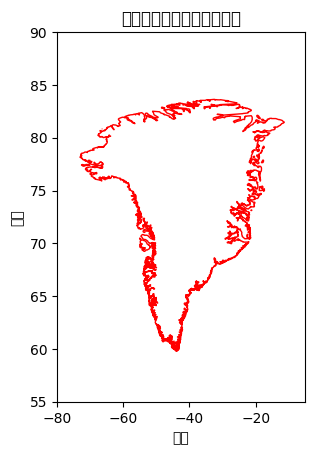

经度范围：-80.0 到 -5.0
纬度范围：55.0 到 90.0

📆 正在处理 1950 年的数据...
该年 snowc 数据维度：(12, 351, 751)
裁剪前 snowc 范围：0.0 ~ 100.0
1950 年 snowc 有效数据：1126500, sde 有效数据：1126500
裁剪后 snowc 范围：0.0 ~ 100.0
✅ 已保存：F:\TUB\greenlandProject\ERA5LAND\snow3para_yearly\greenland_1950.nc

📆 正在处理 1951 年的数据...
该年 snowc 数据维度：(12, 351, 751)
裁剪前 snowc 范围：0.0 ~ 100.0
1951 年 snowc 有效数据：1126500, sde 有效数据：1126500
裁剪后 snowc 范围：0.0 ~ 100.0
✅ 已保存：F:\TUB\greenlandProject\ERA5LAND\snow3para_yearly\greenland_1951.nc

📆 正在处理 1952 年的数据...
该年 snowc 数据维度：(12, 351, 751)
裁剪前 snowc 范围：0.0 ~ 100.0
1952 年 snowc 有效数据：1126500, sde 有效数据：1126500
裁剪后 snowc 范围：0.0 ~ 100.0
✅ 已保存：F:\TUB\greenlandProject\ERA5LAND\snow3para_yearly\greenland_1952.nc

📆 正在处理 1953 年的数据...
该年 snowc 数据维度：(12, 351, 751)
裁剪前 snowc 范围：0.0 ~ 100.0
1953 年 snowc 有效数据：1126500, sde 有效数据：1126500
裁剪后 snowc 范围：0.0 ~ 100.0
✅ 已保存：F:\TUB\greenlandProject\ERA5LAND\snow3para_yearly\greenland_1953.nc

📆 正在处理 1954 年的数据...
该年 snowc 数据维度：(12, 351, 751)
裁剪前 snowc 范围：0.0 ~ 100.0
1954 年 snowc 有效数据：

PermissionError: [Errno 13] Permission denied: 'F:\\TUB\\greenlandProject\\ERA5LAND\\snow3para_yearly\\greenland_1995.nc'

In [32]:
import xarray as xr
import geopandas as gpd
import os
import pandas as pd
import rioxarray
import matplotlib.pyplot as plt

# ========== 配置路径 ==========
nc_path = r"F:\TUB\greenlandProject\ERA5LAND\snow3para.nc"  # 原始全集 nc 文件
shp_path = r"F:\TUB\greenlandProject\ne_10m_admin_0_countries\greenland_boundary.shp"  # 格陵兰边界
output_dir = r"F:\TUB\greenlandProject\ERA5LAND\snow3para_yearly"  # 输出文件夹

# ========== 创建输出目录 ==========
os.makedirs(output_dir, exist_ok=True)

# ========== 读取 shapefile，并设定为 EPSG:4326 ==========
gdf = gpd.read_file(shp_path).to_crs("EPSG:4326")
print(f"Shapefile CRS: {gdf.crs}")

# ========== 需要处理的变量（排除空间参考等变量） ==========
var_list = ["snowc", "sde"]

# ========== 读取 nc 文件并指定坐标系 ==========
ds = xr.open_dataset(nc_path)[var_list]
ds.rio.write_crs("EPSG:4326", inplace=True)
print(f"原始数据 CRS: {ds.rio.crs}")

# ========== 修正经度为 [-180, 180] 范围 ==========
ds = ds.assign_coords({
    "longitude": (((ds.longitude + 180) % 360) - 180)
}).sortby("longitude")

# ========== 打印坐标和变量信息 ==========
print("坐标变量：", list(ds.coords))
print("数据变量：", list(ds.data_vars))

# ========== 获取年份列表 ==========
years = pd.to_datetime(ds.valid_time.values).year
unique_years = sorted(set(years))
print(f"包含年份：{unique_years}")

# ========== 可视化数据范围和格陵兰边界 ==========
plt.figure(figsize=(10, 6))
gdf.plot(edgecolor='red', facecolor='none', label='Greenland Boundary')
plt.xlim(ds.longitude.min(), ds.longitude.max())
plt.ylim(ds.latitude.min(), ds.latitude.max())
plt.title("数据覆盖范围与格陵兰边界")
plt.xlabel("经度")
plt.ylabel("纬度")
plt.show()

# ========== 打印数据地理范围 ==========
print(f"经度范围：{ds.longitude.min().item()} 到 {ds.longitude.max().item()}")
print(f"纬度范围：{ds.latitude.min().item()} 到 {ds.latitude.max().item()}")

# ========== 遍历每一年 ==========
for year in unique_years:
    print(f"\n📆 正在处理 {year} 年的数据...")

    # 按年份筛选时间维度
    ds_year = ds.sel(valid_time=ds.valid_time.dt.year == year)
    print(f"该年 snowc 数据维度：{ds_year['snowc'].shape}")

    # 检查裁剪前的值范围
    snowc_max = float(ds_year["snowc"].max())
    snowc_min = float(ds_year["snowc"].min())
    print(f"裁剪前 snowc 范围：{snowc_min} ~ {snowc_max}")

    # 有效数据检查
    snowc_count = ds_year["snowc"].count().sum().item()
    sde_count = ds_year["sde"].count().sum().item()
    print(f"{year} 年 snowc 有效数据：{snowc_count}, sde 有效数据：{sde_count}")

    if snowc_count == 0 or sde_count == 0:
        print(f"⚠️ {year} 没有有效数据，跳过...")
        continue

    # ========== 按 shapefile 裁剪数据 ==========
    ds_clip = ds_year.rio.clip(gdf.geometry, gdf.crs, drop=False)

    # 裁剪后最大最小值检查
    snowc_clip_max = float(ds_clip["snowc"].max())
    snowc_clip_min = float(ds_clip["snowc"].min())
    print(f"裁剪后 snowc 范围：{snowc_clip_min} ~ {snowc_clip_max}")

    # ========== 保存裁剪后数据 ==========
    out_path = os.path.join(output_dir, f"greenland_{year}.nc")
    ds_clip.to_netcdf(out_path)
    print(f"✅ 已保存：{out_path}")

print("\n🎉 所有年份数据裁剪完成！")



In [ ]:
import xarray as xr
import pandas as pd
import os

# 文件夹路径
folder_path = r"F:\TUB\greenlandProject\ERA5LAND\snow3para_yearly"

# 需要提取的变量
variables = ['snowc', 'sde']

# 获取文件夹内所有的.nc文件
nc_files = [f for f in os.listdir(folder_path) if f.endswith('.nc')]

# 创建一个函数来提取每个文件的数据并保存为CSV
def extract_nc_data_to_csv(nc_file):
    # 读取nc文件
    file_path = os.path.join(folder_path, nc_file)
    ds = xr.open_dataset(file_path)
    
    # 获取经纬度
    lon = ds['longitude'].values
    lat = ds['latitude'].values
    
    # 获取时间并格式化为 year/month
    valid_time = ds['valid_time'].values
    valid_time_pd = pd.to_datetime(valid_time)
    year_month = valid_time_pd.to_series().dt.strftime('%Y/%m').unique()
    
    # 创建一个DataFrame用于存储数据
    data_dict = {'year_month': [], 'longitude': [], 'latitude': []}

    # 获取每个变量的值，并扩展到与经纬度点数一致
    for var in variables:
        if var in ds:
            var_data = ds[var].values  # 获取变量数据
            
            # 扩展数据以匹配经纬度的形状
            # 确保变量的维度顺序为 (时间, 纬度, 经度)
            if var_data.ndim == 3:
                var_data_flat = var_data.reshape(-1)  # 展开为1维
            else:
                continue  # 如果维度不匹配则跳过
                
            data_dict[var] = var_data_flat
            
    # 扩展经纬度数据，并为每个经纬度点和时间点配对
    lon_lat_grid = [(lon[i], lat[j]) for i in range(len(lon)) for j in range(len(lat))]
    year_month_repeated = list(year_month) * len(lon_lat_grid)
    
    data_dict['longitude'] = [lon_lat[0] for lon_lat in lon_lat_grid] * len(year_month)
    data_dict['latitude'] = [lon_lat[1] for lon_lat in lon_lat_grid] * len(year_month)
    
    # 填充year_month列
    data_dict['year_month'] = year_month_repeated
    
    # 创建DataFrame
    df = pd.DataFrame(data_dict)
    
    # 输出CSV文件
    output_csv = os.path.join(folder_path, f"{os.path.splitext(nc_file)[0]}.csv")
    df.to_csv(output_csv, index=False)
    print(f"已保存：{output_csv}")

# 遍历每个.nc文件并提取数据
for nc_file in nc_files:
    extract_nc_data_to_csv(nc_file)


所有变量名： ['spatial_ref', 'snowc', 'sde']
年份跨度： [1988]
月份： [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
snowc 数据最小值： nan
snowc 数据最大值： nan
snowc 数据维度： (12, 351, 751)


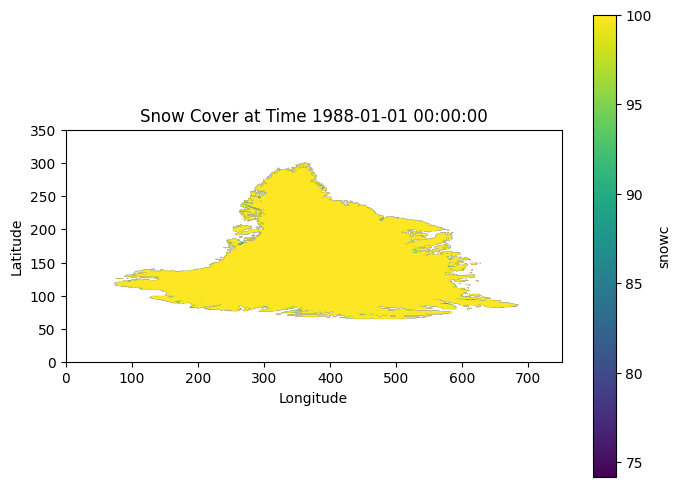

In [38]:
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt

# 读取 nc 文件
file_path = r"F:\TUB\greenlandProject\ERA5LAND\snow3para_yearly\greenland_1988.nc"
ds = xr.open_dataset(file_path)

# 获取所有变量名（去掉坐标变量）
all_vars = list(ds.data_vars)
print("所有变量名：", all_vars)

# 检查 snowc 变量是否存在
if 'snowc' in ds:
    # 提取 snowc 变量数据
    snowc = ds['snowc'].values

    # 获取时间信息并提取年份和月份
    time = ds['valid_time'].values
    time_pd = pd.to_datetime(time)
    years = sorted(set(time_pd.year))
    months = sorted(set(time_pd.month))

    print("年份跨度：", years)
    print("月份：", months)

    # 检查 snowc 的最小值和最大值，确认数据是否合理
    print("snowc 数据最小值：", snowc.min())
    print("snowc 数据最大值：", snowc.max())

    # 检查 snowc 数据的维度
    print("snowc 数据维度：", snowc.shape)

    # 选择第一个时间点的 snowc 数据
    snowc_first_time_point = snowc[0]  # 选择第一个时间点的雪深数据

    # 绘制 snowc 变量的图像
    plt.figure(figsize=(8, 6))
    im = plt.imshow(snowc_first_time_point, cmap='viridis', origin='lower')
    plt.colorbar(im, label='snowc')
    plt.title('Snow Cover at Time {}'.format(time_pd[0]))
    plt.xlabel('Longitude')
    plt.ylabel('Latitude')
    plt.show()
else:
    print("变量 'snowc' 在数据集中不存在。")
